In [8]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
class SoftmaxRegression:
    def __init__(self, learning_rate=0.01, iterations=1000):
        self.lr = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def softmax(self, z):
        """Softmax activation function"""
        exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def loss(self, h, y):
        """Categorical cross-entropy loss using integer labels"""
        m = len(y)
        correct_probs = np.clip(h[np.arange(m), y], 1e-15, 1.0)
        return - (1/m) * np.sum(np.log(correct_probs))

    def fit(self, X, y):
        """Train model using gradient descent"""
        m, n = X.shape
        y = y.astype(int)
        k = np.max(y) + 1
        rows = np.arange(m)

        self.weights = np.zeros((n, k))
        self.bias = np.zeros((1, k))

        for _ in range(self.iterations):
            z = np.dot(X, self.weights) + self.bias
            h = self.softmax(z)

            self.loss_history.append(self.loss(h, y))

            grad = h.copy()
            grad[rows, y] -= 1

            dw = (1/m) * np.dot(X.T, grad)
            db = (1/m) * np.sum(grad, axis=0, keepdims=True)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        """Make predictions"""
        z = np.dot(X, self.weights) + self.bias
        h = self.softmax(z)
        return np.argmax(h, axis=1)

In [12]:
train_img_path = "../dataset/train/train-images.idx3-ubyte"
train_label_path = "../dataset/train/train-labels.idx1-ubyte"

X_train = np.fromfile(train_img_path, dtype=np.uint8, offset=16).reshape(-1, 784) / 255.0
y_train = np.fromfile(train_label_path, dtype=np.uint8, offset=8)

print("Images shape:", X_train.shape)
print("Unique classes:", np.unique(y_train))

Images shape: (60000, 784)
Unique classes: [0 1 2 3 4 5 6 7 8 9]


In [11]:
test_img_path = "../dataset/test/t10k-images.idx3-ubyte"
test_label_path = "../dataset/test/t10k-labels.idx1-ubyte"

X_test = np.fromfile(test_img_path, dtype=np.uint8, offset=16).reshape(-1, 784) / 255.0
y_test = np.fromfile(test_label_path, dtype=np.uint8, offset=8)

print("Images shape:", X_test.shape)
print("Unique classes:", np.unique(y_test))

Images shape: (10000, 784)
Unique classes: [0 1 2 3 4 5 6 7 8 9]


In [13]:
model = SoftmaxRegression(learning_rate=0.01, iterations=1000)
model.fit(X_train, y_train)

In [14]:
predictions = model.predict(X_test)
y_true = y_test.astype(int)
classes = np.unique(y_true)

precisions, recalls, f1s = [], [], []

for c in classes:
    tp = np.sum((predictions == c) & (y_true == c))
    fp = np.sum((predictions == c) & (y_true != c))
    fn = np.sum((predictions != c) & (y_true == c))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    precisions.append(precision)
    recalls.append(recall)
    f1s.append(f1)

    print(f"Class {c} -> Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")

print("-" * 58)
print(f"Macro Avg -> Precision: {np.mean(precisions):.4f} | Recall: {np.mean(recalls):.4f} | F1: {np.mean(f1s):.4f}")

Class 0 -> Precision: 0.9087 | Recall: 0.9653 | F1: 0.9362
Class 1 -> Precision: 0.9037 | Recall: 0.9595 | F1: 0.9308
Class 2 -> Precision: 0.8905 | Recall: 0.8198 | F1: 0.8537
Class 3 -> Precision: 0.8453 | Recall: 0.8713 | F1: 0.8581
Class 4 -> Precision: 0.8624 | Recall: 0.8809 | F1: 0.8715
Class 5 -> Precision: 0.8737 | Recall: 0.7287 | F1: 0.7946
Class 6 -> Precision: 0.8781 | Recall: 0.9175 | F1: 0.8974
Class 7 -> Precision: 0.9007 | Recall: 0.8648 | F1: 0.8824
Class 8 -> Precision: 0.8090 | Recall: 0.8306 | F1: 0.8197
Class 9 -> Precision: 0.8317 | Recall: 0.8474 | F1: 0.8395
----------------------------------------------------------
Macro Avg -> Precision: 0.8704 | Recall: 0.8686 | F1: 0.8684


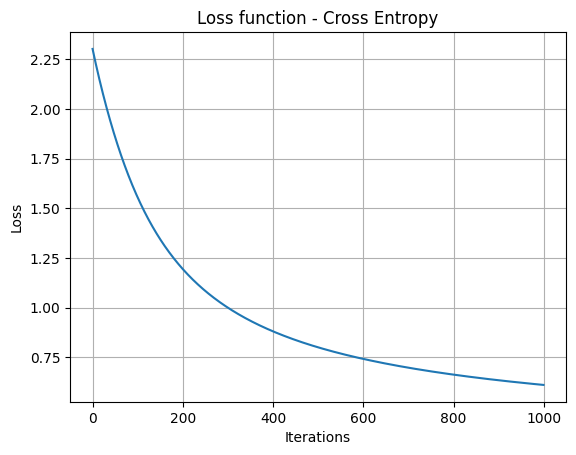

In [15]:
plt.plot(model.loss_history)
plt.title("Loss function - Cross Entropy")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid(True)
plt.show()